<a href="https://colab.research.google.com/github/rithishacs24-lab/BIS-LAB/blob/main/gray.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

City Coordinates:
City 0: X=37.45, Y=95.07
City 1: X=73.20, Y=59.87
City 2: X=15.60, Y=15.60
City 3: X=5.81, Y=86.62
City 4: X=60.11, Y=70.81
City 5: X=2.06, Y=96.99
City 6: X=83.24, Y=21.23
City 7: X=18.18, Y=18.34
City 8: X=30.42, Y=52.48
City 9: X=43.19, Y=29.12
Iteration   1 | Best Distance: 424.89
Iteration   2 | Best Distance: 417.86
Iteration   3 | Best Distance: 407.29
Iteration   4 | Best Distance: 376.44
Iteration   5 | Best Distance: 348.98
Iteration   6 | Best Distance: 415.81
Iteration   7 | Best Distance: 380.53
Iteration   8 | Best Distance: 389.85
Iteration   9 | Best Distance: 374.78
Iteration  10 | Best Distance: 314.76
Iteration  11 | Best Distance: 374.65
Iteration  12 | Best Distance: 354.53
Iteration  13 | Best Distance: 333.11
Iteration  14 | Best Distance: 345.49
Iteration  15 | Best Distance: 350.07
Iteration  16 | Best Distance: 355.68
Iteration  17 | Best Distance: 355.68
Iteration  18 | Best Distance: 345.49
Iteration  19 | Best Distance: 345.50
Iteration  2

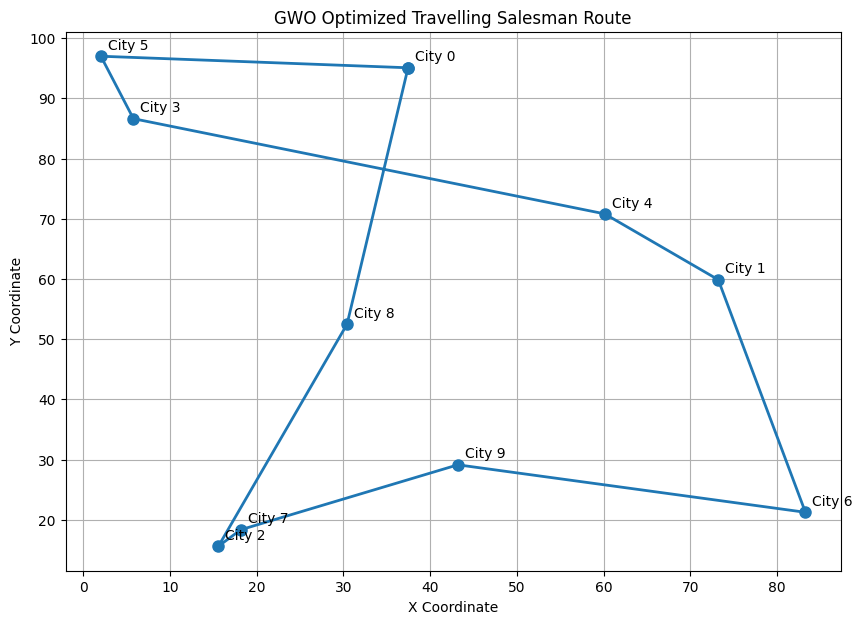

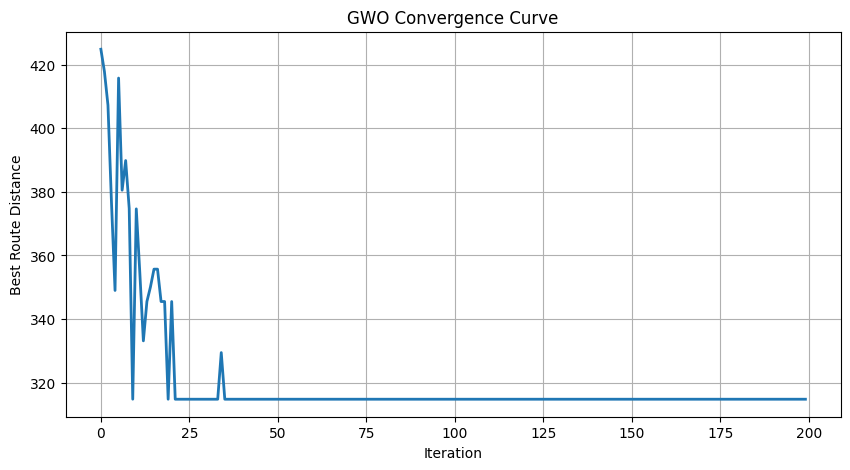

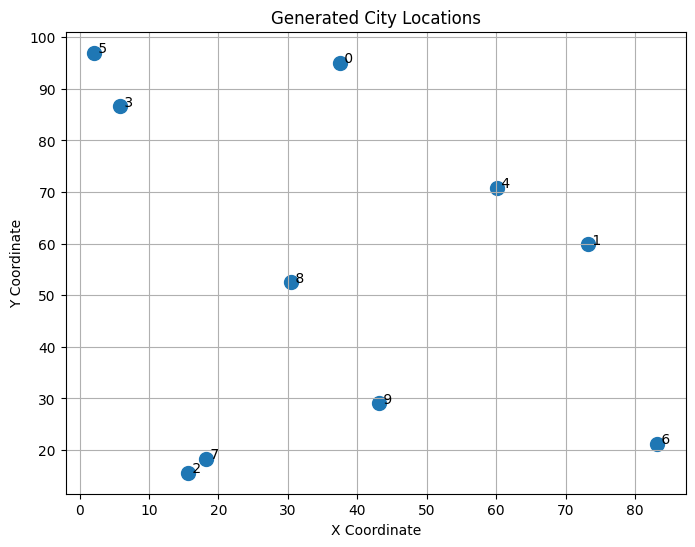


Route Details:


,From City,To City,Distance
0,0,5,35.45
1,5,3,11.03
2,3,4,56.56
3,4,1,17.06
4,1,6,39.92
5,6,9,40.82
6,9,7,27.24
7,7,2,3.76
8,2,8,39.74
9,8,0,43.17



Excel file generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# ============================================================
# GRAY WOLF OPTIMIZATION (GWO)
# APPLICATION: TRAVELLING SALESMAN PROBLEM (TSP)
# GOOGLE COLAB IMPLEMENTATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
from scipy.spatial.distance import cdist
from IPython.display import display

# -------------------------------
# 1. PARAMETERS
# -------------------------------

NUM_CITIES = 10
NUM_WOLVES = 40
MAX_ITERATIONS = 200

START_CITY = 0
np.random.seed(42)
random.seed(42)

# -------------------------------
# 2. GENERATE CITY LOCATIONS
# -------------------------------

cities = np.random.rand(NUM_CITIES, 2) * 100

distance_matrix = cdist(cities, cities, metric='euclidean')

print("City Coordinates:")
for i, city in enumerate(cities):
    print(f"City {i}: X={city[0]:.2f}, Y={city[1]:.2f}")

# -------------------------------
# 3. ROUTE DECODING
# -------------------------------

def decode_wolf(wolf):
    """
    Convert continuous wolf position into
    a valid city permutation.

    City 0 is always the starting city.
    """
    route = np.argsort(wolf) + 1
    return np.concatenate(([START_CITY], route))


# -------------------------------
# 4. FITNESS FUNCTION
# -------------------------------

def calculate_distance(route):

    total_distance = 0

    for i in range(len(route) - 1):
        total_distance += distance_matrix[
            route[i], route[i + 1]
        ]

    # Return to starting city
    total_distance += distance_matrix[
        route[-1], route[0]
    ]

    return total_distance


def fitness_function(wolf):

    route = decode_wolf(wolf)

    return calculate_distance(route)


# -------------------------------
# 5. INITIALIZE WOLF POPULATION
# -------------------------------

wolves = np.random.rand(NUM_WOLVES, NUM_CITIES - 1)

fitness = np.array([
    fitness_function(wolf) for wolf in wolves
])

# Sort wolves by fitness
sorted_indices = np.argsort(fitness)

alpha = wolves[sorted_indices[0]].copy()
beta = wolves[sorted_indices[1]].copy()
delta = wolves[sorted_indices[2]].copy()

alpha_score = fitness[sorted_indices[0]]

best_history = []

# -------------------------------
# 6. GRAY WOLF OPTIMIZATION
# -------------------------------

for iteration in range(MAX_ITERATIONS):

    # Parameter decreases from 2 to 0
    a = 2 - 2 * iteration / MAX_ITERATIONS

    for i in range(NUM_WOLVES):

        current = wolves[i].copy()

        # Random coefficients
        r1 = np.random.rand(NUM_CITIES - 1)
        r2 = np.random.rand(NUM_CITIES - 1)

        A1 = 2 * a * r1 - a
        C1 = 2 * r2

        D_alpha = np.abs(C1 * alpha - current)
        X1 = alpha - A1 * D_alpha

        r1 = np.random.rand(NUM_CITIES - 1)
        r2 = np.random.rand(NUM_CITIES - 1)

        A2 = 2 * a * r1 - a
        C2 = 2 * r2

        D_beta = np.abs(C2 * beta - current)
        X2 = beta - A2 * D_beta

        r1 = np.random.rand(NUM_CITIES - 1)
        r2 = np.random.rand(NUM_CITIES - 1)

        A3 = 2 * a * r1 - a
        C3 = 2 * r2

        D_delta = np.abs(C3 * delta - current)
        X3 = delta - A3 * D_delta

        # Update wolf position
        new_position = (X1 + X2 + X3) / 3

        # Keep position within bounds
        new_position = np.clip(new_position, 0, 1)

        wolves[i] = new_position

    # Evaluate new population
    fitness = np.array([
        fitness_function(wolf) for wolf in wolves
    ])

    # Identify top three wolves
    sorted_indices = np.argsort(fitness)

    alpha = wolves[sorted_indices[0]].copy()
    beta = wolves[sorted_indices[1]].copy()
    delta = wolves[sorted_indices[2]].copy()

    alpha_score = fitness[sorted_indices[0]]

    best_history.append(alpha_score)

    print(
        f"Iteration {iteration + 1:3d} | "
        f"Best Distance: {alpha_score:.2f}"
    )

# -------------------------------
# 7. FINAL BEST ROUTE
# -------------------------------

best_route = decode_wolf(alpha)
best_distance = calculate_distance(best_route)

# Add starting city at the end
complete_route = np.append(best_route, START_CITY)

print("\n========== FINAL RESULTS ==========")

print("Best Route:")
print(" -> ".join(map(str, complete_route)))

print(f"\nMinimum Distance: {best_distance:.2f}")

print("\nRoute Validation:")
print("All cities visited exactly once:",
      len(set(best_route)) == NUM_CITIES)

print("Correct number of cities:",
      len(best_route) == NUM_CITIES)

print("Returns to starting city:",
      complete_route[0] == complete_route[-1])

# -------------------------------
# 8. ROUTE VISUALIZATION
# -------------------------------

plt.figure(figsize=(10, 7))

route_coordinates = cities[complete_route]

plt.plot(
    route_coordinates[:, 0],
    route_coordinates[:, 1],
    'o-',
    linewidth=2,
    markersize=8
)

for i, (x, y) in enumerate(cities):
    plt.annotate(
        f"City {i}",
        (x, y),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.title("GWO Optimized Travelling Salesman Route")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True)
plt.show()

# -------------------------------
# 9. CONVERGENCE GRAPH
# -------------------------------

plt.figure(figsize=(10, 5))

plt.plot(best_history, linewidth=2)

plt.title("GWO Convergence Curve")
plt.xlabel("Iteration")
plt.ylabel("Best Route Distance")
plt.grid(True)
plt.show()

# -------------------------------
# 10. CITY COORDINATE GRAPH
# -------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(cities[:, 0], cities[:, 1], s=100)

for i, (x, y) in enumerate(cities):
    plt.text(x, y, f" {i}")

plt.title("Generated City Locations")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True)
plt.show()

# -------------------------------
# 11. ROUTE DETAILS TABLE
# -------------------------------

route_details = []

for i in range(len(complete_route) - 1):

    city_from = complete_route[i]
    city_to = complete_route[i + 1]

    distance = distance_matrix[city_from, city_to]

    route_details.append({
        "From City": city_from,
        "To City": city_to,
        "Distance": round(distance, 2)
    })

df = pd.DataFrame(route_details)

print("\nRoute Details:")
display(df)

# -------------------------------
# 12. EXPORT TO EXCEL
# -------------------------------

with pd.ExcelWriter("GWO_TSP_Results.xlsx") as writer:

    df.to_excel(
        writer,
        sheet_name="Best Route",
        index=False
    )

    pd.DataFrame(
        cities,
        columns=["X Coordinate", "Y Coordinate"]
    ).to_excel(
        writer,
        sheet_name="City Coordinates",
        index_label="City"
    )

    pd.DataFrame({
        "Iteration": range(1, len(best_history) + 1),
        "Best Distance": best_history
    }).to_excel(
        writer,
        sheet_name="Convergence",
        index=False
    )

print("\nExcel file generated successfully!")

# Download Excel file in Google Colab
from google.colab import files
files.download("GWO_TSP_Results.xlsx")
